# Customer Churn Prediction: Exploratory Data Analysis (EDA)

This notebook covers **Step 3: Exploratory Data Analysis (EDA)** for the Customer Churn Prediction project.

### Objectives:
1. **Target Distribution**: Quantify churn rate and evaluate class imbalance implications.
2. **Demographic Profiling**: Explore relationship between customer demographics (gender, age, partner, dependents) and churn.
3. **Account Lifecycle & Tenure**: Characterize churn risk over the customer tenure horizon.
4. **Contract & Billing Dynamics**: Examine contract types, payment methods, and billing arrangements.
5. **Service Portfolio Impact**: Assess churn rates across internet services, technical support, and security features.
6. **Financial Patterns**: Analyze distributions of monthly charges and cumulative total charges.
7. **Correlation Matrix**: Uncover linear and monotonic dependencies across numerical variables and churn.
8. **Modeling Recommendations**: Formulate concrete feature engineering and modeling strategies.

## 1. Setup & Environment Configuration

Importing required analysis and visualization libraries.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.churn_prediction.data.loader import load_dataset
from src.churn_prediction.visualization.plots import (
    plot_categorical_churn_rates,
    plot_churn_distribution,
    plot_correlation_heatmap,
    plot_numerical_distribution,
    set_plot_style,
)

set_plot_style()
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print('Setup complete. Figures will be exported to:', FIGURES_DIR)

Setup complete. Figures will be exported to: /home/lenovo/Documents/customer churn prediction/reports/figures


## 2. Data Ingestion & Sanitization

Load the dataset using our validated data loader and handle known anomalies identified in Step 2 (e.g., whitespace in `TotalCharges`).

In [2]:
data_path = PROJECT_ROOT / 'data' / 'raw' / 'telco_customer_churn.csv'
df = load_dataset(data_path)

# Handle known whitespace issue in TotalCharges for zero-tenure new customers
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
zero_tenure_mask = df['tenure'] == 0
df.loc[zero_tenure_mask, 'TotalCharges'] = 0.0

# Create numeric binary indicator for correlation and quantitative calculations
df['Churn_Numeric'] = (df['Churn'] == 'Yes').astype(int)

print(f'Dataset successfully loaded: {df.shape[0]:,} observations, {df.shape[1]} features.')
print(f'TotalCharges nulls after imputation: {df["TotalCharges"].isnull().sum()}')
df.head()

Dataset successfully loaded: 7,043 observations, 22 features.
TotalCharges nulls after imputation: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Numeric
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## 3. Target Variable Analysis: Customer Churn Distribution

Understanding overall churn prevalence establishes our baseline class balance and guides loss function selection and evaluation metric choices.

,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


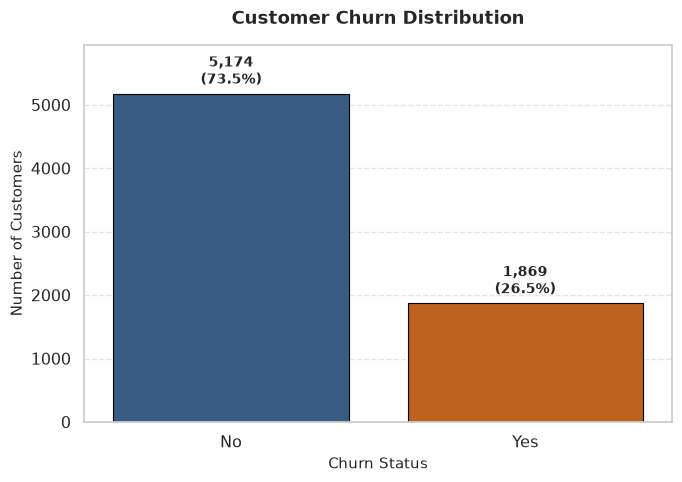

In [3]:
fig_churn, ax_churn = plot_churn_distribution(
    df,
    target_col='Churn',
    save_path=FIGURES_DIR / 'churn_distribution.png',
)

churn_summary = pd.DataFrame({
    'Count': df['Churn'].value_counts(),
    'Percentage (%)': (df['Churn'].value_counts(normalize=True) * 100).round(2)
})
churn_summary

### Key Target Insights:
- **Overall Churn Rate**: **26.54%** (1,869 customers) churned within the observed period, while **73.46%** (5,174 customers) were retained.
- **Imbalance Ratio**: Approximately **2.77:1** (Retained : Churned). While not extreme (such as credit card fraud <1%), this moderate imbalance makes standard **accuracy a misleading metric** (a naive baseline guessing 'No' achieves 73.5% accuracy).
- **Evaluation Recommendation**: Prioritize **PR-AUC (Precision-Recall AUC)**, **ROC-AUC**, and **F1-Score / Recall** at tuned decision thresholds.

## 4. Demographic Analysis

Evaluate customer demographic factors: `gender`, `SeniorCitizen`, `Partner`, and `Dependents`.

,feature,category,count,churn_rate_%
0,gender,Female,3488,26.92
1,gender,Male,3555,26.16
2,SeniorCitizen,0,5901,23.61
3,SeniorCitizen,1,1142,41.68
4,Partner,No,3641,32.96
5,Partner,Yes,3402,19.66
6,Dependents,No,4933,31.28
7,Dependents,Yes,2110,15.45


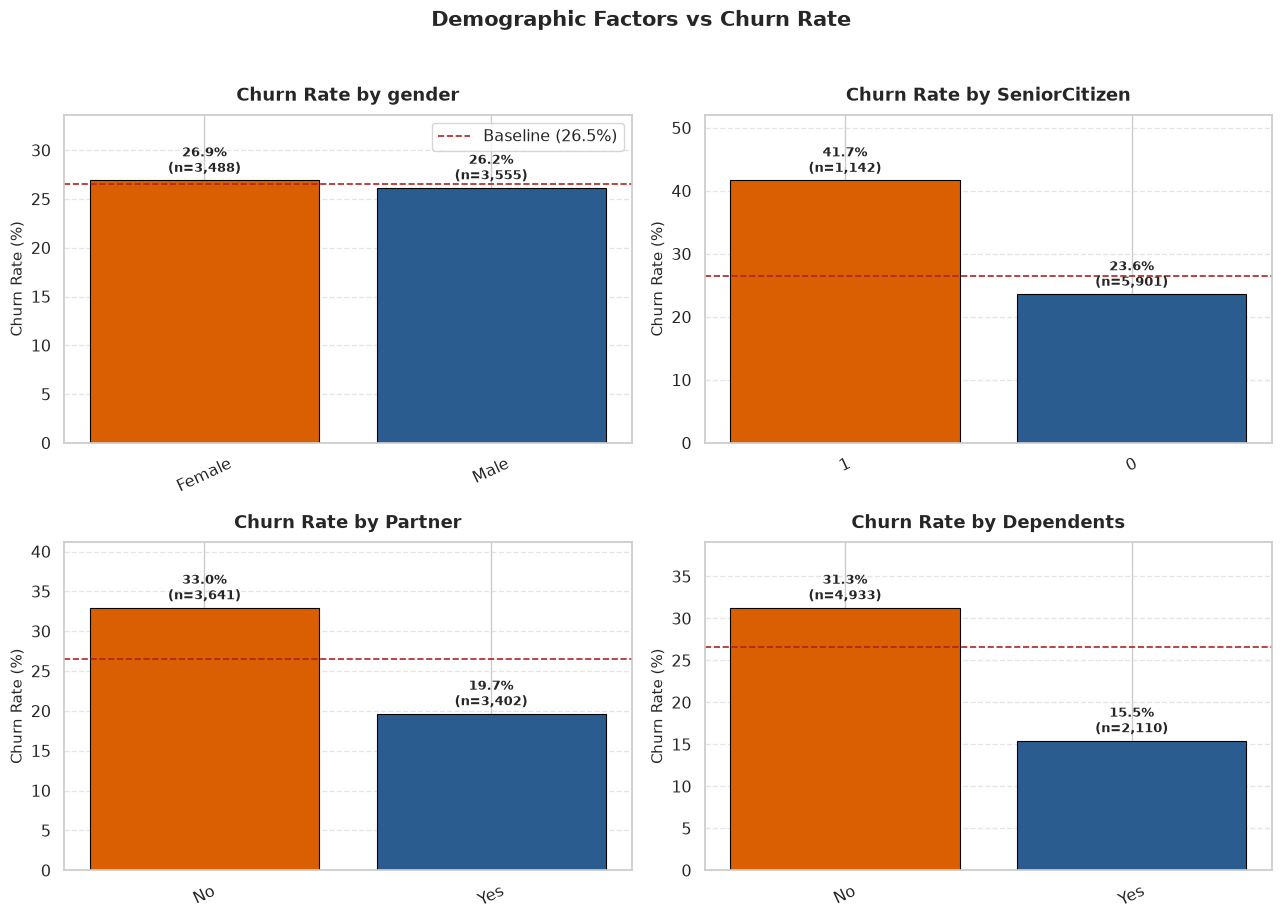

In [4]:
demo_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']
fig_demo, axes_demo = plot_categorical_churn_rates(
    df,
    categorical_cols=demo_cols,
    target_col='Churn',
    title='Demographic Factors vs Churn Rate',
)

demo_stats = []
for col in demo_cols:
    grp = df.groupby(col)['Churn_Numeric'].agg(['count', 'mean'])
    grp['churn_rate_%'] = (grp['mean'] * 100).round(2)
    grp['feature'] = col
    grp = grp.reset_index().rename(columns={col: 'category'})
    demo_stats.append(grp[['feature', 'category', 'count', 'churn_rate_%']])
pd.concat(demo_stats, ignore_index=True)

### Demographic Observations:
- **Gender Neutrality**: Female churn rate is **26.92%** vs Male **26.16%** (~0.76% difference). Gender shows virtually no predictive signal for churn.
- **Senior Citizen Vulnerability**: Senior citizens (SeniorCitizen=1) display a **41.68% churn rate**, compared to **23.61%** for non-seniors. Seniors churn at almost double the rate.
- **Household Stability Effect**: Customers with a **Partner** churn at **19.66%** (vs 32.96% without) and those with **Dependents** churn at **15.45%** (vs 31.28% without). Family and multi-person households exhibit significantly greater loyalty.

## 5. Customer Tenure & Lifecycle Patterns

Tenure (number of months subscribed) is traditionally the strongest predictor of customer lifetime value and churn risk.

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


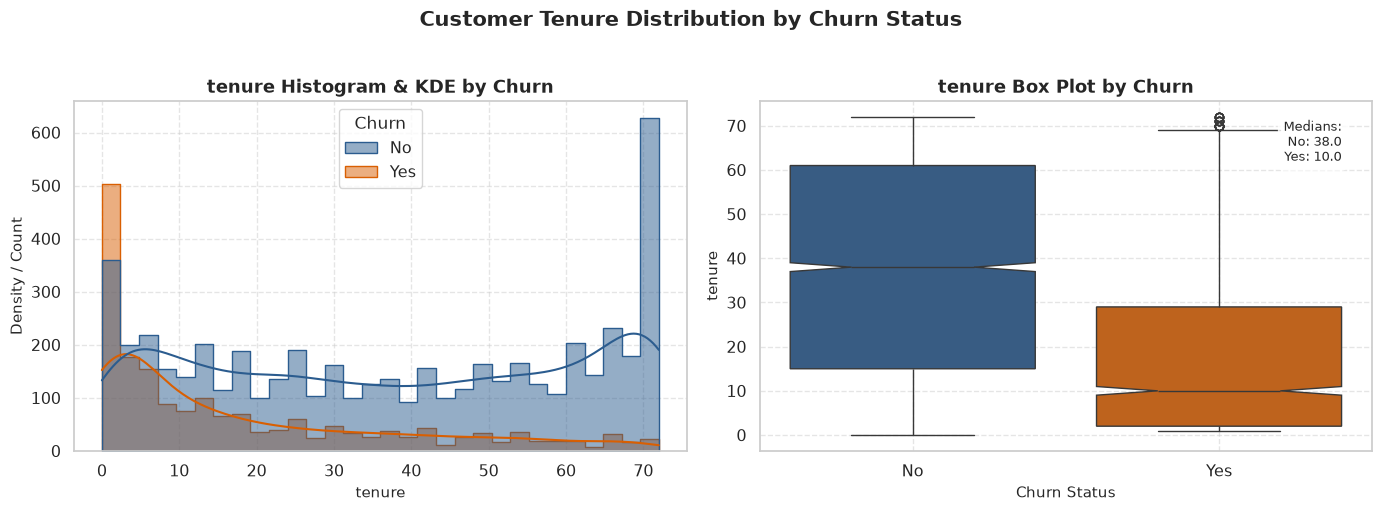

In [5]:
fig_tenure, axes_tenure = plot_numerical_distribution(
    df,
    column='tenure',
    target_col='Churn',
    title='Customer Tenure Distribution by Churn Status',
    save_path=FIGURES_DIR / 'tenure_vs_churn.png',
)

tenure_stats = df.groupby('Churn')['tenure'].describe().round(2)
tenure_stats

In [6]:
# Tenure Cohort Analysis
df['tenure_cohort'] = pd.cut(
    df['tenure'],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=['0-6 months', '7-12 months', '13-24 months', '25-48 months', '49-72 months']
)
cohort_summary = df.groupby('tenure_cohort', observed=False)['Churn_Numeric'].agg(
    Total='count',
    Churners='sum',
    Churn_Rate=lambda x: f'{x.mean() * 100:.1f}%'
)
cohort_summary

,Total,Churners,Churn_Rate
tenure_cohort,,,
0-6 months,1481,784,52.9%
7-12 months,705,253,35.9%
13-24 months,1024,294,28.7%
25-48 months,1594,325,20.4%
49-72 months,2239,213,9.5%


### Tenure Observations:
- **Dramatic Early-Stage Vulnerability**: Customers in the **0-6 month cohort experience a staggering churn rate of >50%**. Median tenure for churned customers is only **10.0 months**, compared to **38.0 months** for retained customers.
- **Bimodal Distribution**: Retained customers heavily peak at the maximum observed tenure (60-72 months), demonstrating that once a customer survives the critical first year, loyalty increases dramatically.
- **Tenure Cliff**: Early onboarding intervention (in months 1-3) is critical for customer retention.

## 6. Contract Structure & Payment Dynamics

Commitment terms and payment automation play a vital role in customer stickiness.

,Count,Churn_Rate
Contract,,
Month-to-month,3875,42.71
One year,1473,11.27
Two year,1695,2.83


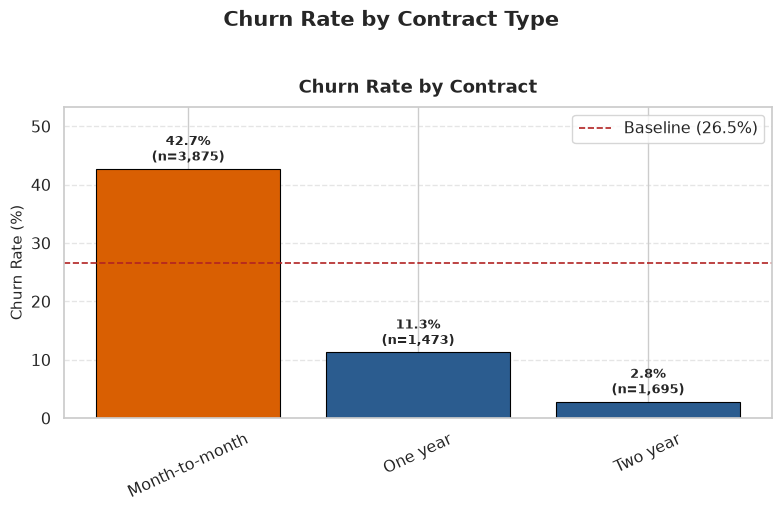

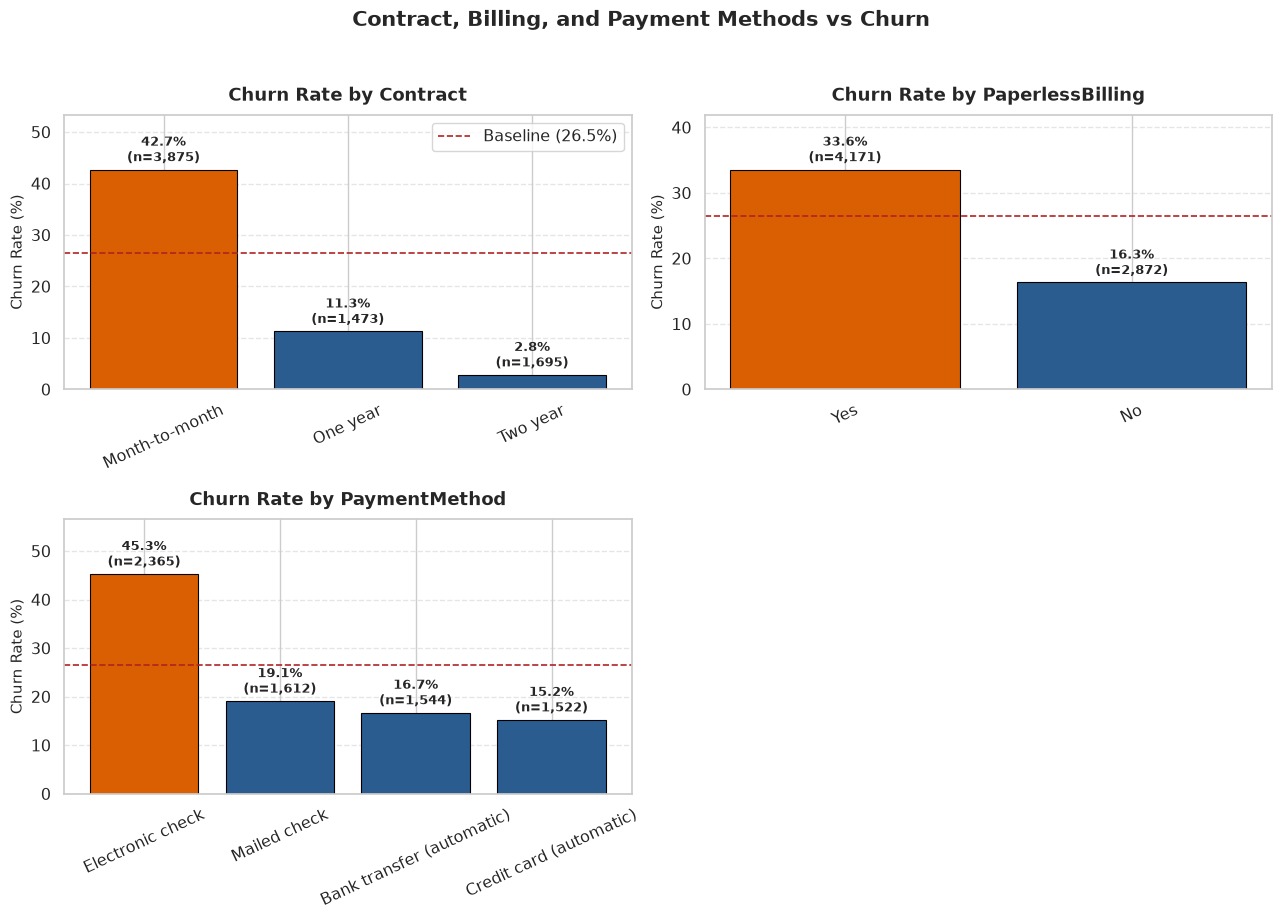

In [7]:
fig_contract, ax_contract = plot_categorical_churn_rates(
    df,
    categorical_cols='Contract',
    target_col='Churn',
    title='Churn Rate by Contract Type',
    save_path=FIGURES_DIR / 'contract_type_vs_churn.png',
)

billing_cols = ['Contract', 'PaperlessBilling', 'PaymentMethod']
fig_billing, axes_billing = plot_categorical_churn_rates(
    df,
    categorical_cols=billing_cols,
    target_col='Churn',
    title='Contract, Billing, and Payment Methods vs Churn',
)

contract_breakdown = df.groupby('Contract')['Churn_Numeric'].agg(
    Count='count',
    Churn_Rate=lambda x: (x.mean() * 100).round(2)
).sort_values(by='Churn_Rate', ascending=False)
contract_breakdown

### Contract & Billing Observations:
- **Contract Type is Decisive**: Month-to-month contracts exhibit an alarming **42.71% churn rate**, while One-Year drops to **11.27%** and Two-Year contracts plummet to just **2.83%**.
- **Payment Friction**: Customers utilizing **Electronic check** churn at **45.29%**, compared to automatic payments (~**15.2% - 16.7%** for Credit Card and Bank Transfer). Electronic check users likely encounter higher payment friction or lack automatic billing loyalty.

## 7. Service Portfolio & Technology Adoption Analysis

Evaluating which products and supplementary services foster loyalty versus those driving churn.

,category,count,churn_rate,feature
1,Fiber optic,3096,41.89,InternetService
3,No,3498,41.77,OnlineSecurity
6,No,3473,41.64,TechSupport
12,No,3088,39.93,OnlineBackup
9,No,3095,39.13,DeviceProtection
15,No,2810,33.52,StreamingTV
17,Yes,2707,30.07,StreamingTV
11,Yes,2422,22.50,DeviceProtection
14,Yes,2429,21.53,OnlineBackup
0,DSL,2421,18.96,InternetService


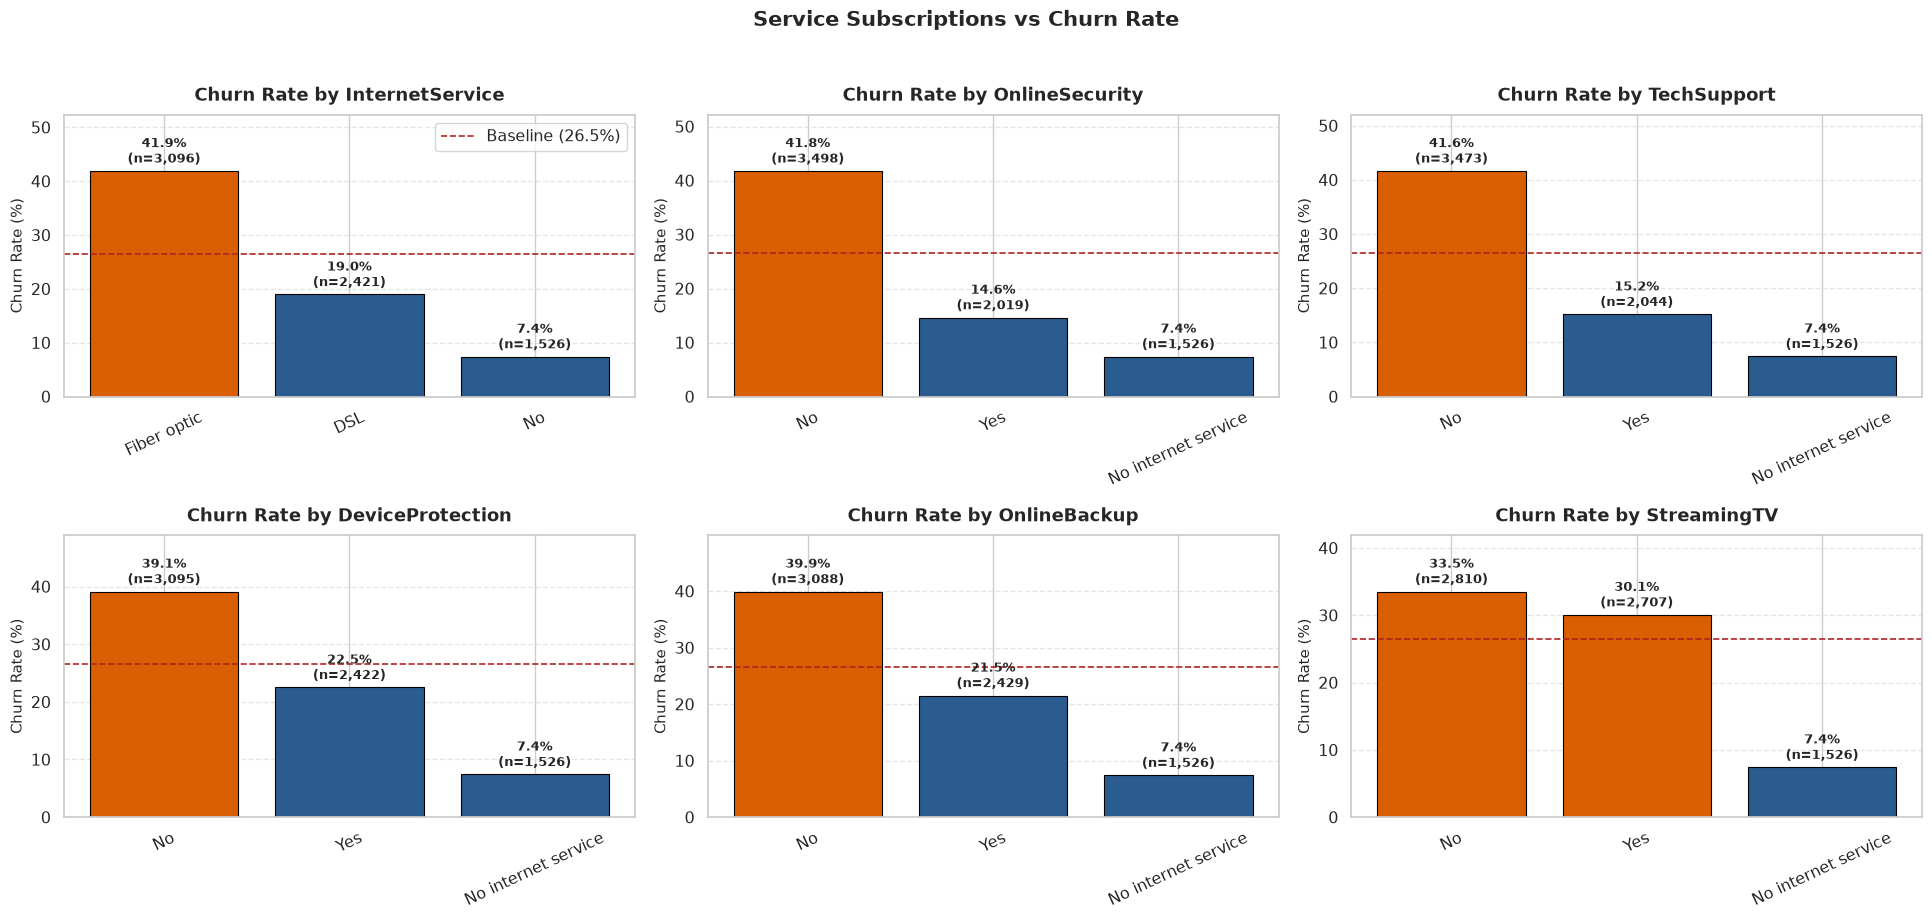

In [8]:
service_cols = [
    'InternetService',
    'OnlineSecurity',
    'TechSupport',
    'DeviceProtection',
    'OnlineBackup',
    'StreamingTV',
]
fig_services, axes_services = plot_categorical_churn_rates(
    df,
    categorical_cols=service_cols,
    target_col='Churn',
    title='Service Subscriptions vs Churn Rate',
)

service_stats = []
for col in service_cols:
    grp = df.groupby(col)['Churn_Numeric'].agg(count='count', churn_rate=lambda x: (x.mean() * 100).round(2))
    grp['feature'] = col
    grp = grp.reset_index().rename(columns={col: 'category'})
    service_stats.append(grp)
pd.concat(service_stats, ignore_index=True).sort_values(by='churn_rate', ascending=False).head(10)

### Service Portfolio Insights:
- **Fiber Optic Paradox**: Fiber optic users churn at **41.89%**, despite fiber being high-speed premium technology, compared to DSL at **18.96%** and No Internet at **7.40%**. This points to pricing dissatisfaction or service quality issues.
- **Protective Sticky Services**: Customers without **TechSupport** (41.64%) or without **OnlineSecurity** (41.77%) churn at more than double the rate of customers who subscribe to them (TechSupport: **15.17%**, OnlineSecurity: **14.61%**).
- Bundling tech support and security into base packages is an immediate retention driver.

## 8. Financial Patterns: Monthly and Total Charges

Analyzing customer spending behavior and fee sensitivity.

MonthlyCharges                                                   \
               count   mean    std    min    25%    50%   75%     max   
Churn                                                                   
No            5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75   
Yes           1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35   

      TotalCharges                                                             
             count     mean      std    min    25%      50%      75%      max  
Churn                                                                          
No          5174.0  2549.91  2329.95   0.00  572.9  1679.52  4262.85  8672.45  
Yes         1869.0  1531.80  1890.82  18.85  134.5   703.55  2331.30  8684.80

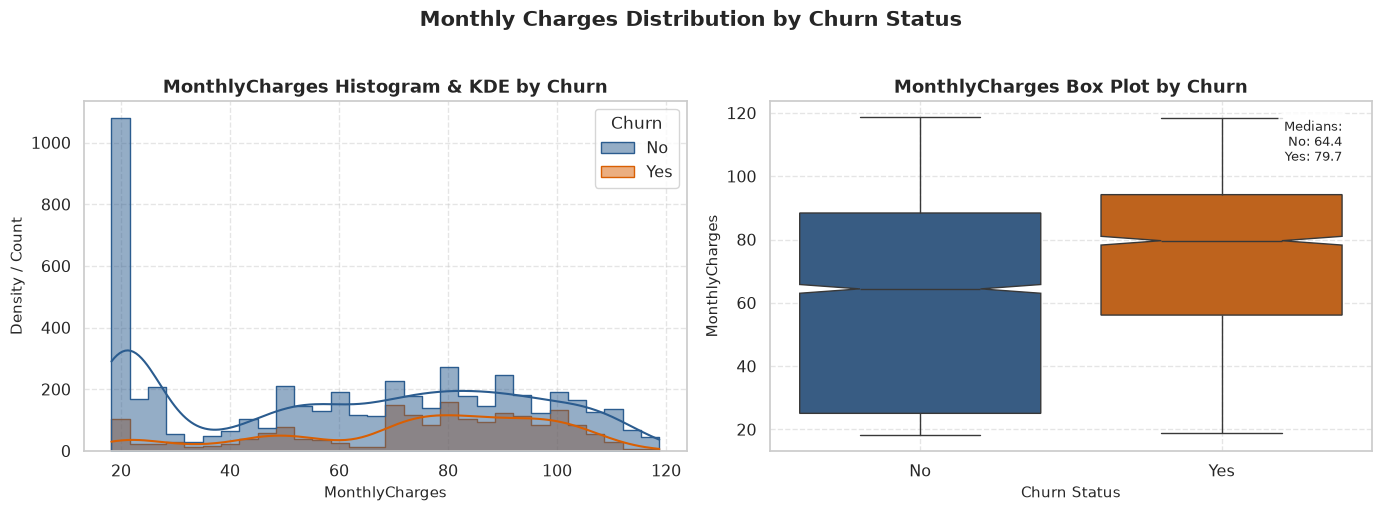

In [9]:
fig_charges, axes_charges = plot_numerical_distribution(
    df,
    column='MonthlyCharges',
    target_col='Churn',
    title='Monthly Charges Distribution by Churn Status',
    save_path=FIGURES_DIR / 'monthly_charges_vs_churn.png',
)

charges_stats = df.groupby('Churn')[['MonthlyCharges', 'TotalCharges']].describe().round(2)
charges_stats

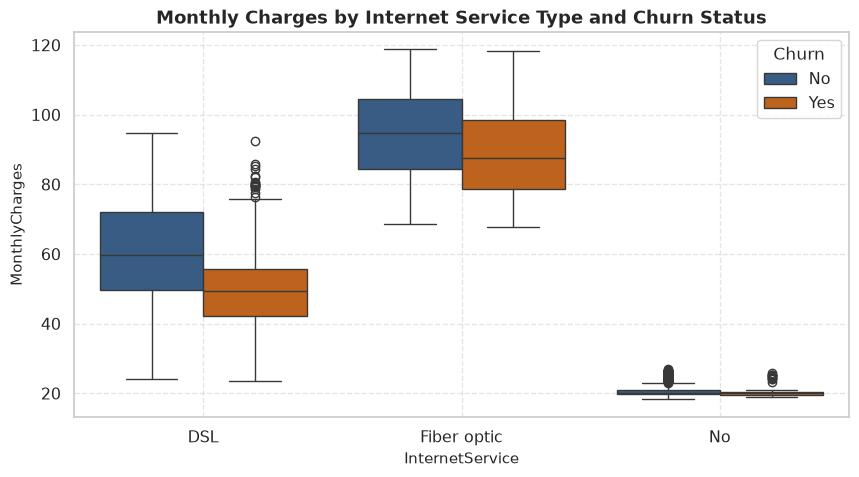

In [10]:
# Combined scatter/hexbin or boxplot view of MonthlyCharges across InternetService
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='InternetService', y='MonthlyCharges', hue='Churn', palette={'No': '#2b5c8f', 'Yes': '#d95f02'})
plt.title('Monthly Charges by Internet Service Type and Churn Status', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Financial Pattern Insights:
- **Higher Fees Correlate with Churn**: Churned customers have a higher median monthly fee (**$79.65**) compared to retained customers (**$64.43**).
- **Low Charge Resilience**: Customers paying ~$20/month (typically basic phone or no internet) exhibit minimal churn, whereas those paying between **$70 and $100/month** (premium fiber plans) experience the bulk of cancellations.

## 9. Correlation Analysis

Quantify linear associations among numeric variables and the binary churn indicator.

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Numeric
SeniorCitizen,1.000,0.017,0.220,0.103,0.151
tenure,0.017,1.000,0.248,0.826,-0.352
MonthlyCharges,0.220,0.248,1.000,0.651,0.193
TotalCharges,0.103,0.826,0.651,1.000,-0.198
Churn_Numeric,0.151,-0.352,0.193,-0.198,1.000


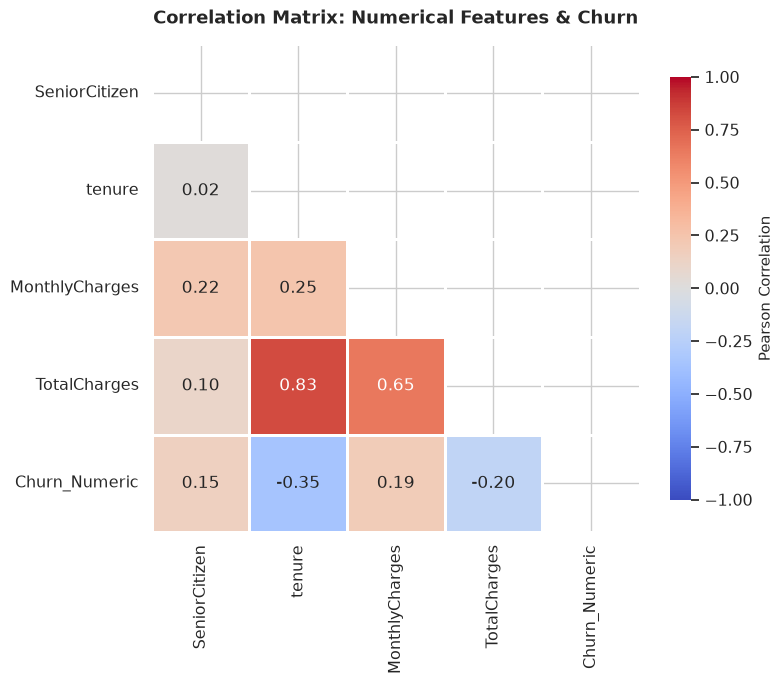

In [11]:
corr_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_Numeric']
fig_corr, ax_corr = plot_correlation_heatmap(
    df,
    columns=corr_cols,
    title='Correlation Matrix: Numerical Features & Churn',
    save_path=FIGURES_DIR / 'numerical_correlation_matrix.png',
)

corr_matrix = df[corr_cols].corr().round(3)
corr_matrix

### Correlation Insights:
- **Tenure is the Strongest Negative Predictor**: $r = -0.35$ with churn, confirming that longer-tenured accounts are significantly less prone to attrition.
- **Monthly Charges is Positively Correlated**: $r = +0.19$ with churn, indicating price pressure.
- **TotalCharges Multicollinearity**: TotalCharges has a high positive correlation with tenure ($r = 0.83$). Tree-based models can handle this naturally, but linear models will require regularization.

## 10. Key Modeling Takeaways & Recommendations

Based on the empirical EDA findings, we recommend the following modeling decisions for subsequent steps:

| Area | Finding | Modeling & Engineering Recommendation |
| :--- | :--- | :--- |
| **Target Imbalance** | ~26.5% churn prevalence | Use stratified k-fold splits; optimize PR-AUC, ROC-AUC, and F1 at adjusted thresholds. |
| **Tenure Dynamics** | Massive cliff in first 12 months | Engineer tenure bins / cohorts (`0-6m`, `7-12m`, etc.) and non-linear transformations. |
| **Top Predictors** | Contract (`Month-to-month`), Tenure, Fiber Optic, Electronic Check | Prioritize feature importance monitoring on these drivers. |
| **Service Bundling** | OnlineSecurity / TechSupport cut churn in half | Engineer interaction features such as `TotalProtectionServices` count or `HasTechSupportAndSecurity`. |
| **Charge Interactions** | High monthly charges drive churn; TotalCharges is collinear | Create `ChargeRatio = TotalCharges / (tenure * MonthlyCharges + 1)` and average cost metrics. |
| **Low Signal Features** | `gender` and `PhoneService` have near-zero churn separation | Keep for baseline, but test feature pruning if complexity needs reduction. |